### Top Rows

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# -------------------------------------------------
# 1. Replace "x" with 1800 in ORIGINAL df (in place)
# -------------------------------------------------

file_path = "results-filtered-dataset.txt"

# Read the first sheet
# df = pd.read_excel(file_path)
df = pd.read_csv(file_path, sep=r"\s+")

sp_noAltRB = ["UMKP-S", "UMKP-R", "UMKP-P"]
sp_AltRB = ["UMKP+-S", "UMKP+-R", "UMKP+-P"]
dense = ["kPEX"]

sparse = sp_AltRB + sp_noAltRB
all_algos = sparse + dense

df[all_algos] = df[all_algos].replace("x", 1800).apply(pd.to_numeric)


In [7]:
df["sparse_min"] = df[sparse].min(axis=1)
df["dense_min"] = df[dense].min(axis=1)

df["ratio"] = np.maximum(df["sparse_min"], df["dense_min"]) / np.minimum(df["sparse_min"], df["dense_min"])

filtered_rows = df[
    (df["sparse_min"] > 1) &
    (df["dense_min"] > 1) &
    (df["ratio"] >= 10)
].sort_values(by="ratio", ascending=False).copy()

# Split into two tables
sparse_wins_table = filtered_rows[filtered_rows["sparse_min"] < filtered_rows["dense_min"]]
dense_wins_table  = filtered_rows[filtered_rows["dense_min"] < filtered_rows["sparse_min"]]

total = len(filtered_rows)

display(Markdown(f"""
## Experiment Summary
### Filtered rows: **{total}**
- Sparse faster: **{len(sparse_wins_table)}**
- Dense faster: **{len(dense_wins_table)}**
"""))

display(Markdown("## Sparse Wins"))
print(sparse_wins_table[["dataset", "k", "sparse_min", "dense_min", "ratio"]])

display(Markdown("## Dense Wins"))
print(dense_wins_table[["dataset", "k", "sparse_min", "dense_min", "ratio"]])


## Experiment Summary
### Filtered rows: **284**
- Sparse faster: **271**
- Dense faster: **13**


## Sparse Wins

                       dataset   k  sparse_min  dense_min        ratio
3732                    ted_AB   9    1.032514  1800.0000  1743.317766
3734                    ted_AB  15    1.033251  1800.0000  1742.074288
3738           ted_AB_unscaled   9    1.039869  1800.0000  1730.987269
3740           ted_AB_unscaled  15    1.131578  1800.0000  1590.699006
2214              mult_dcop_03   8    1.424235  1800.0000  1263.836375
...                        ...  ..         ...        ...          ...
3628                 std1_Jac2   2  174.418400  1800.0000    10.320012
1779                    IG5-15   7    5.095684    52.5353    10.309764
3908          TSOPF_FS_b162_c4   4    5.721298    58.5625    10.235877
2780                  raefsky3   7    4.562500    46.5167    10.195441
562   bookcrossing_full-rating  20  178.015600  1800.0000    10.111473

[271 rows x 5 columns]


## Dense Wins

            dataset   k   sparse_min  dense_min       ratio
4324   wiki-topcats  20  1800.000000    16.3664  109.981425
516   bibsonomy-2ut  20   244.912000     2.4535   99.821480
4130  web-ClueWeb09  15  1417.348800    15.4648   91.649992
2037       MANN-a45  15  1800.000000    28.5184   63.117145
3712           t520  20   222.937711     3.7555   59.362991
2066      Maragal_6  15  1800.000000    31.0583   57.955522
1878    lastfm_band   6  1800.000000    55.1463   32.640449
1687           hood  20    34.002900     1.3949   24.376586
2954   san200-0-9-1   2  1800.000000    92.5738   19.443946
443        bcsstk39  20    42.075039     2.3834   17.653369
1364   flickr-links  15  1800.000000   146.7472   12.265992
1162    edit-viwiki  15   546.133100    45.2436   12.070947
2639       pkustk10  20   192.942156    19.2146   10.041435


### Winning Algorithm Counts

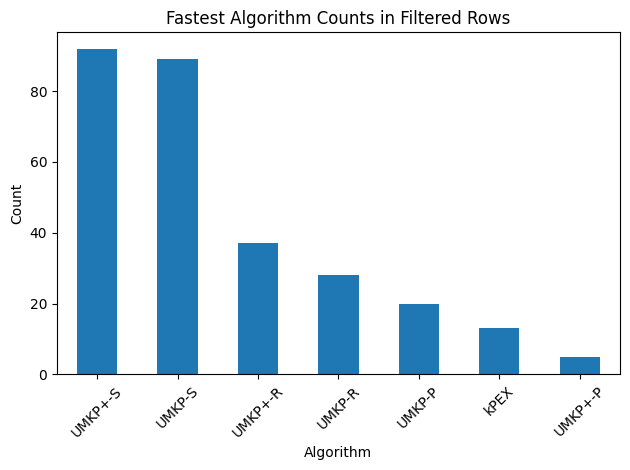

In [8]:
# algorithm that is fastest per row
filtered_rows["fastest_algo"] = filtered_rows[all_algos].idxmin(axis=1)

# count occurrences
algo_counts = filtered_rows["fastest_algo"].value_counts()

algo_counts.plot(kind="bar")

plt.xlabel("Algorithm")
plt.ylabel("Count")
plt.title("Fastest Algorithm Counts in Filtered Rows")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Varying Ratio Threshold

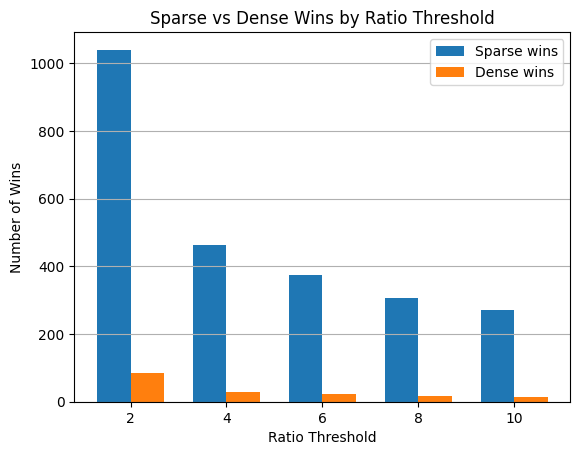

In [9]:
ratio_thresholds = [2, 4, 6, 8, 10]

sparse_wins_list = []
dense_wins_list = []

df["ratio"] = np.maximum(df["sparse_min"], df["dense_min"]) / np.minimum(df["sparse_min"], df["dense_min"])

for r in ratio_thresholds:
    filtered_rows = df[
        (df["sparse_min"] > 1) &
        (df["dense_min"] > 1) &
        (df["ratio"] >= r)
    ]

    total = len(filtered_rows)
    sparse_wins = (filtered_rows["sparse_min"] < filtered_rows["dense_min"]).sum()
    dense_wins = total - sparse_wins

    sparse_wins_list.append(sparse_wins)
    dense_wins_list.append(dense_wins)

# Bar chart
x = np.arange(len(ratio_thresholds))
width = 0.35

plt.figure()
plt.bar(x - width/2, sparse_wins_list, width, label="Sparse wins")
plt.bar(x + width/2, dense_wins_list, width, label="Dense wins")

plt.xticks(x, ratio_thresholds)
plt.xlabel("Ratio Threshold")
plt.ylabel("Number of Wins")
plt.title("Sparse vs Dense Wins by Ratio Threshold")
plt.legend()
plt.grid(axis="y")

plt.show()